# AI Certification Landscape
## What does the published credential catalog tell us?
A reproducible data science project using **AI Course Check**, by Jake Boland. [Dataset and attribution](https://aicoursecheck.com/data/) · [Repository](https://github.com/jakeboland/ai-certifications-dataset).

Questions: Which issuers and levels appear in this catalog? How much information is disclosed? How do listed prices vary within currency and billing groups? Can text similarity retrieve related credentials?

This is a catalog snapshot, not a representative sample of the whole market. There are no learner outcomes, salaries, popularity measures or independent quality labels. We use descriptive analysis and information retrieval rather than an unsupported prediction target.

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.analysis import load, normalize, missingness, price_summary, recommend, run
from IPython.display import display, SVG
payload = load()
credentials, prices, delivery = normalize(payload)
print('Snapshot:', payload['generated_at'])
print('Credentials:', len(credentials), '| Issuers:', credentials.issuer.nunique())
credentials[['name', 'issuer_name', 'kind', 'level', 'status']].head(10)

Snapshot: 2026-11-01
Credentials: 77 | Issuers: 22
Out[1]: 
                                                name  ...         status
0           Claude Certified Architect - Foundations  ...         active
1          Claude Certified Architect - Professional  ...         active
2           Claude Certified Associate - Foundations  ...         active
3           Claude Certified Developer - Foundations  ...         active
4                        AWS Agentic AI Demonstrated  ...         active
5               AWS Certified AI Business Strategist  ...           beta
6                      AWS Certified AI Practitioner  ...         active
7  AWS Certified Generative AI Developer - Profes...  ...         active
8  AWS Certified Machine Learning Engineer - Asso...  ...  transitioning
9         AWS Certified Machine Learning - Specialty  ...        retired

[10 rows x 5 columns]


## Data model and integrity
The raw JSON is preserved. Credentials, price options and delivery modes become separate tables to prevent nested rows from inflating credential counts. Null means **not stated by the issuer**. False is an observed value, not missing; an empty list differs from null.

Load-time checks catch duplicate identifiers, count mismatches, negative prices and contradictory expiry fields. Prices retain label, currency, billing, tax and region. Launch dates retain their original month/day precision.

{
  "source": "https://github.com/jakeboland/ai-certifications-dataset",
  "canonical_source": "https://aicoursecheck.com/data/",
  "generated_at": "2026-11-01",
  "sha256": "43e7bbc108374a9ea97c1ed3876287a5233becf71b131bdf8490e3d08d98e964",
  "records": 77,
  "issuers": 22,
  "price_rows": 76,
  "statuses": {
    "active": 65,
    "retired": 5,
    "announced": 3,
    "beta": 2,
    "transitioning": 1,
    "pilot": 1
  },
  "price_disclosed_credentials": 59,
  "null_means": "not stated by the issuer"
}


credentials
kind               status                    
assessment         active                   1
course-certificate active                  10
                   pilot                    1
exam               active                  48
                   announced                3
                   beta                     2
                   retired                  5
                   transitioning            1
microcredential    active                   6

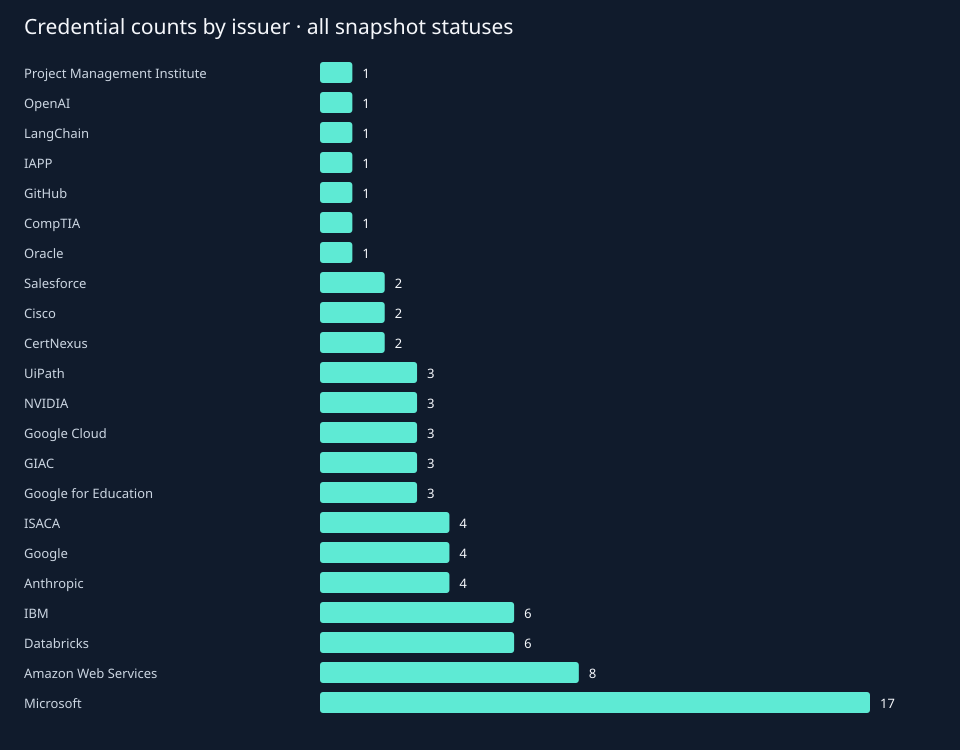

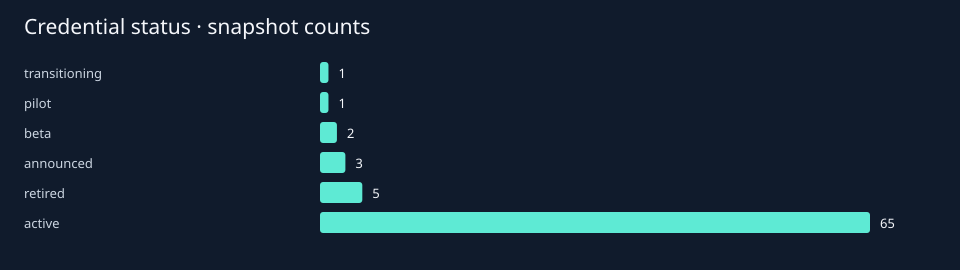

In [2]:
run()
display(credentials.groupby(['kind', 'status']).size().rename('credentials').to_frame())
display(SVG(filename=str(ROOT / 'results/issuers.svg')))
display(SVG(filename=str(ROOT / 'results/statuses.svg')))

## Disclosure and accessibility
Missingness describes this dataset's disclosures. It is not a provider-quality score: some fields are not applicable to some credential kinds. Delivery options overlap, so mode counts can exceed the number of credentials. Counts include all statuses unless explicitly filtered.

,field,missing_count,missing_pct
24,replaced_by,76,98.701299
22,launch_date,75,97.402597
18,no_expiry,75,97.402597
23,retirement_date,71,92.207792
26,official_prep,65,84.415584
8,credential_code,62,80.519481
29,last_changed,61,79.220779
15,question_count,53,68.831169
19,renewal,52,67.532468
16,passing_score,49,63.636364


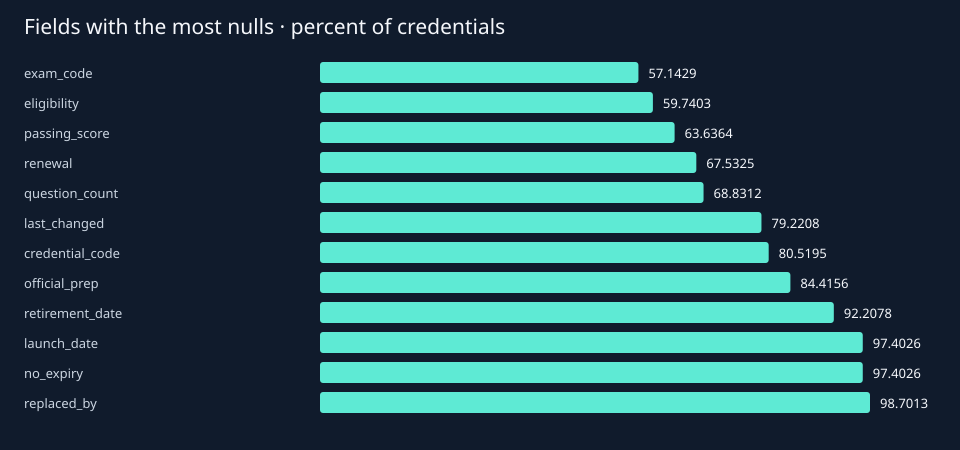

,credentials_offering_mode
delivery_mode,
online-proctored,29
test-center,25
self-paced,13
online-assessment,5


,credentials
expiry_category,
fixed term stated,41
not stated,34
no expiry stated,2


,count
level,
not stated,40
associate,18
foundational,8
professional,8
expert,2
specialty,1


In [3]:
display(missingness(payload).head(15))
display(SVG(filename=str(ROOT / 'results/missingness.svg')))
display(delivery.delivery_mode.value_counts().rename('credentials_offering_mode').to_frame())
display(credentials.expiry_category.value_counts().rename('credentials').to_frame())
display(credentials.level.fillna('not stated').value_counts().to_frame())

## Price structure
The table below summarizes **price rows**, not independent credentials. Member, regional, beta and standard options can belong to one credential. Currency, billing, label and tax are grouped separately; region notes remain in the detailed price table. Even within these groups, geographic eligibility and inclusions may differ. Medians describe the catalog and do not establish affordability or value.

No currency conversions, null-to-zero filling, annualized monthly prices, or cross-provider passing-score comparisons are performed. A stated zero price with unknown currency remains in its own group.

In [4]:
display(price_summary(prices))
display(prices[['name', 'status', 'label', 'amount', 'currency', 'billing', 'tax', 'region_note']].head(20))
print('Credentials with listed prices:', int(credentials.price_disclosed.sum()), '/', len(credentials))

Credentials with listed prices: 59 / 77


,currency,billing,label,tax,price_rows,credentials,minimum,median,maximum
0,AUD,one-off,standard,not-stated,3,3,150.0,224.0,449.0
1,JPY,one-off,retake,plus-tax,1,1,15000.0,15000.0,15000.0
2,JPY,one-off,standard,plus-tax,1,1,30000.0,30000.0,30000.0
3,USD,one-off,beta,not-stated,2,2,50.0,62.5,75.0
4,USD,one-off,beta,plus-tax,1,1,120.0,120.0,120.0
5,USD,one-off,member,not-stated,5,5,120.0,459.0,649.0
6,USD,one-off,non-member,not-stated,5,5,144.0,599.0,799.0
7,USD,one-off,retake,plus-tax,3,3,100.0,899.0,899.0
8,USD,one-off,standard,not-stated,28,28,99.0,165.0,367.5
9,USD,one-off,standard,plus-tax,10,10,99.0,200.0,999.0


,name,status,label,amount,currency,billing,tax,region_note
0,AWS Certified AI Business Strategist,beta,beta,50.0,USD,one-off,not-stated,NaN
1,AWS Certified AI Business Strategist,beta,standard,100.0,USD,one-off,not-stated,NaN
2,AWS Certified AI Practitioner,active,standard,100.0,USD,one-off,not-stated,NaN
3,AWS Certified AI Practitioner,active,standard,150.0,AUD,one-off,not-stated,Countries that use the Australian dollar
4,AWS Certified Generative AI Developer - Profes...,active,standard,300.0,USD,one-off,not-stated,NaN
5,AWS Certified Generative AI Developer - Profes...,active,standard,449.0,AUD,one-off,not-stated,Countries that use the Australian dollar
6,AWS Certified Machine Learning Engineer - Asso...,transitioning,standard,150.0,USD,one-off,not-stated,NaN
7,AWS Certified Machine Learning Engineer - Asso...,transitioning,beta,75.0,USD,one-off,not-stated,NaN
8,AWS Certified Machine Learning Engineer - Asso...,transitioning,standard,224.0,AUD,one-off,not-stated,Countries that use the Australian dollar
9,AWS Certified Machine Learning - Specialty,retired,standard,300.0,USD,one-off,not-stated,NaN


## Text similarity experiment
A small, explainable TF-IDF retriever uses title, issuer, tier, credential kind and official preparation text. Cosine similarity measures lexical overlap, not credential quality or suitability. Only credentials marked active in the snapshot are eligible by default. Issuer vocabulary and repeated preparation copy can dominate results. Unseen query terms are ignored; a query with no known terms returns no results.

Try several queries and inspect the matched terms and original issuer links. This experiment has no human relevance labels, so it reports no fabricated accuracy score. A next evaluation would label query–credential pairs independently and measure precision@5 against a simple keyword baseline.

In [5]:
query = 'generative AI developer professional'
results = recommend(query, payload)
display(__import__('pandas').DataFrame(results))
assert recommend('zzzzunseenword', payload) == []

,id,name,issuer,similarity,matched_terms,source_urls
0,aws-certified-generative-ai-developer-professi...,AWS Certified Generative AI Developer - Profes...,Amazon Web Services,0.6499,"[ai, developer, generative, professional]",[https://aws.amazon.com/blogs/training-and-cer...
1,ibm-ai-developer-professional-certificate,IBM AI Developer Professional Certificate,IBM,0.4996,"[ai, developer, professional]",[https://www.coursera.org/professional-certifi...
2,ibm-generative-ai-engineering-professional-cer...,IBM Generative AI Engineering Professional Cer...,IBM,0.3619,"[ai, generative, professional]",[https://www.coursera.org/professional-certifi...
3,microsoft-sql-ai-developer-associate-dp-800,Microsoft Certified: SQL AI Developer Associate,Microsoft,0.3168,"[ai, developer]",[https://learn.microsoft.com/en-us/credentials...
4,databricks-generative-ai-fundamentals,Generative AI Fundamentals,Databricks,0.2938,"[ai, generative]",[https://www.databricks.com/learn/certificatio...


## Interpretation and next steps
Use the generated summary and plots to describe this particular catalog. Issuer counts reflect coverage, not market share. Historical changes are not reconstructed from a single snapshot. Prices and status may have changed since the snapshot; check linked issuer pages before making a purchase.

A stronger follow-up would collect versioned snapshots for longitudinal analysis and create independently labeled relevance judgments for retrieval evaluation. Career ROI or pass-probability modeling would require new outcome data.

The source data is licensed CC BY 4.0. Attribution: **AI Course Check (aicoursecheck.com)**, https://aicoursecheck.com/data/. See `data/raw/LICENSE` and `CITATION.cff`. The processed tables and derived features are adaptations; upstream source facts are preserved in the bundled raw file.